## 3.2 State Reducer
### 3.2.1 what is state reducer?
从教程来看, 在代码里体现为一个函数，来定义 一个 字段的 更新方式。

Reducer 的核心特征：

- 函数签名：`(Value, Value) -> Value`，接收当前值和更新值，返回合并后的新值
- 注解定义：通过 `Annotated[Type, reducer_function]` 为状态键指定 Reducer
- 默认行为：未指定 Reducer 的状态键使用覆盖策略（Last-Write-Wins）

In [ ]:
def reducer_add(left: str,right: str) -> str:
    """
    合并两个字符串，返回一个字符串，字符串之间用 "->" 连接

    Args:
        left: 从最开始的位置合并到当前节点位置的值，即当前已累计的状态值
        right: 当前节点的值，即本次待合并的新值

    """
    return left + "->" + right

from langgraph.graph import StateGraph, START, END
from typing import  Annotated
from operator import add
from dataclasses import dataclass
from rich import print as rprint

@dataclass
class OverAllState:
    logs: Annotated[list[str], add]
    cur_id: Annotated[str, reducer_add]

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    #节点返回的 dict 并不会被转换成 OverAllState。LangGraph 会把它按字段拆开，逐个交给对应字段的 reducer 合并；没有 reducer 的字段直接覆盖。
    #下一个节点收到的 dataclass 实例，是根据当前所有字段的值重新构建出来的。
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": "node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": "node_2"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

rprint(graph.invoke({"cur_id": "start"}))


{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': '->start->node_1->node_2'}

起点设置为 start时,仍然会在 left 处出现一个 空字符串。

langgraph 框架内部会读取 字典绑定的 Reducer 函数。当多个节点同时更新 `logs` 字段时，LangGraph 会使用 `my_reducer` 将多个列表合并；

### 3.2.2 测试原来的并行图

In [5]:
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph,START,END
from langgraph.graph import StateGraph



class OverAllstate(TypedDict):
    """
    全局状态，用于存储全局变量
    基础状态类

    """
    # 注解是为了规定字段,这里表明 logs更新的方式是 add而不是替代
    # 第一个参数 list[str]: 告诉静态类型检查器（如 mypy、IDE）以及开发者：这个变量是一个字符串列表（list of strings）
    # 第二个参数 add: 定义追加的方式。langgraph内部会读取第二个参数,然后以这种方式更新 logs
    logs: Annotated[list[str], add]
    cur_id: Annotated[str, reducer_add]

# 节点实际就是一个函数
def node_1(state: OverAllstate) -> OverAllstate:
    """
    节点 1
    """
    return {
        "logs": ["node_1 运行完毕"],
        "cur_id": "node_1"
    }

# 节点实际就是一个函数
def node_2(state: OverAllstate) -> OverAllstate:
    """
    节点 2
    """
    return {
        # 以追加的方式更新
        "logs": ["node_2 运行完毕"],
        "cur_id": "node_2"
    }
#节点实际就是一个函数
def node_3(state: OverAllstate) -> OverAllstate:
    """
    节点 3
    """
    return {
        # 以追加的方式更新
        "logs": ["node_3 运行完毕"],
        "cur_id": "node_3"
    }

# 3 定义边 与 图
# 3.1 创建图 获取建造者
builder = StateGraph(state_schema=OverAllstate)
# 3.2 添加节点
# 这里传入的是函数对象。LangGraph 保存它，并默认使用函数名 "node_1" 作为节点名，因此后面可以用这个字符串连接边。节点执行时，框架传入当前状态，接收它返回的字段更新；节点可以只返回需要更新的字段。
builder.add_node(node_1)
builder.add_node(node_2)
builder.add_node(node_3)
# 3.2 添加边
# 3.2.1
# 3.3 添加边
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_1","node_3")
# 陷入循环会 报错 超过调用次数: GraphRecursionError: Recursion limit of 10007 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
# builder.add_edge("node_2","node_1")
builder.add_edge("node_2", END)
builder.add_edge("node_3",END)

# 4 获取图
# 校验图结构，构造可执行图，此时还没有运行你们的两个业务节点。
graph = builder.compile()

# 5 运行图
# invoke: 初始状态
result = graph.invoke({"cur_id":"start"})
rprint(result)

{'logs': ['node_1 运行完毕', 'node_2 运行完毕', 'node_3 运行完毕'], 'cur_id': '->start->node_1->node_2->node_3'}

最后的输出比较意外，`'cur_id': '->start->node_1->node_2->node_3'` 

langgraph的框架内部在节点更新的时候，`.venv/lib/python3.11/site-packages/langgraph/pregel/_algo.py` 代码实际进行了节点排序
```python
# 按任务路径排序，确保应用更新的顺序是确定的
tasks = sorted(tasks, key=lambda t: task_path_str(t.path[:3]))
```

因此即使让 node_2 先暂停5秒，最后输出也是 3号节点在后。

In [7]:
for chunk in graph.stream({"cur_id": "start"}, stream_mode="debug"):
    rprint(chunk)

{
    'step': 1,
    'timestamp': '2026-10-13T13:45:00.435192+00:00',
    'type': 'task',
    'payload': {
        'id': '25e6310e-cea8-ecb7-e18e-e55dc3f26259',
        'name': 'node_1',
        'input': {'logs': [], 'cur_id': '->start'},
        'triggers': ('branch:to:node_1',)
    }
}

{
    'step': 1,
    'timestamp': '2026-10-13T13:45:00.437726+00:00',
    'type': 'task_result',
    'payload': {
        'id': '25e6310e-cea8-ecb7-e18e-e55dc3f26259',
        'name': 'node_1',
        'error': None,
        'result': {'logs': ['node_1 运行完毕'], 'cur_id': 'node_1'},
        'interrupts': []
    }
}

{
    'step': 2,
    'timestamp': '2026-10-13T13:45:00.437908+00:00',
    'type': 'task',
    'payload': {
        'id': '25710a0c-41e6-da37-e002-625c90b55b64',
        'name': 'node_2',
        'input': {'logs': ['node_1 运行完毕'], 'cur_id': '->start->node_1'},
        'triggers': ('branch:to:node_2',)
    }
}

{
    'step': 2,
    'timestamp': '2026-10-13T13:45:00.437914+00:00',
    'type': 'task',
    'payload': {
        'id': '05ce589c-6a81-91db-ba62-ff6ed55a3029',
        'name': 'node_3',
        'input': {'logs': ['node_1 运行完毕'], 'cur_id': '->start->node_1'},
        'triggers': ('branch:to:node_3',)
    }
}

{
    'step': 2,
    'timestamp': '2026-10-13T13:45:00.441806+00:00',
    'type': 'task_result',
    'payload': {
        'id': '25710a0c-41e6-da37-e002-625c90b55b64',
        'name': 'node_2',
        'error': None,
        'result': {'logs': ['node_2 运行完毕'], 'cur_id': 'node_2'},
        'interrupts': []
    }
}

{
    'step': 2,
    'timestamp': '2026-10-13T13:45:00.443134+00:00',
    'type': 'task_result',
    'payload': {
        'id': '05ce589c-6a81-91db-ba62-ff6ed55a3029',
        'name': 'node_3',
        'error': None,
        'result': {'logs': ['node_3 运行完毕'], 'cur_id': 'node_3'},
        'interrupts': []
    }
}

### 3.2.3  常用内置Reducer函数
1. operator.add: 允许参数是列表

2. langgraph.graph.message.add_messages

`add_messages` 是 LangGraph 中专用于合并消息列表的 Reducer 函数，常用于维护对话历史类的状态字段。其函数签名如下：

```python
def add_messages(
    left: Messages,
    right: Messages,
    *,
    format: Literal["langchain-openai"] | None = None,
) -> Messages:
    ...
    return merged
```

参数说明：

- `left`：状态中已有的消息列表；
- `right`：当前节点返回的消息更新值；
- `format`：可选参数，用于指定返回消息的格式，通常无需手动设置。

这个函数的更新方式与我们在 langchain 里做的笔记一致: 
* 若 `right` 中的某条消息的 `id` 在 `left` 中不存在，则将该消息追加到结果列表末尾；
* 若 `right` 中的某条消息的 `id` 与 `left` 中已有消息的 `id` 相同，则使用 `right` 中的新消息替换 `left` 中的旧消息。

In [8]:
from langgraph.graph.message import add_messages
from langchain.messages import HumanMessage, AIMessage, SystemMessage

left = [
    SystemMessage(content="你是个善解人意的助手", id='1'),
    HumanMessage(content="你好", id='2'),
    AIMessage(content="你好~", id='3'),
]

right = [
    HumanMessage(content="我是老王，你是小王", id='2'),
    AIMessage(content="好的，我记住啦", id='3'),
    HumanMessage(content="你是谁？", id='4'),
    AIMessage(content="我是小王", id='5'),
]

merged = add_messages(left, right)

for msg in merged:
    print(msg)

content='你是个善解人意的助手' additional_kwargs={} response_metadata={} id='1'
content='我是老王，你是小王' additional_kwargs={} response_metadata={} id='2'
content='好的，我记住啦' additional_kwargs={} response_metadata={} id='3' tool_calls=[] invalid_tool_calls=[]
content='你是谁？' additional_kwargs={} response_metadata={} id='4'
content='我是小王' additional_kwargs={} response_metadata={} id='5' tool_calls=[] invalid_tool_calls=[]


## 3.3 节点中访问State

### 3.3.1 图节点中读取State
1. 在 LangGraph 中，节点本质上是一个可调用对象，通常定义为普通 Python 函数。
2. 节点函数的第一个参数通常是当前运行图的状态对象，也就是 `State`。

下面是使用节点函数读取state 数据


In [9]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState):
    for k, v in state.items():
        print(f"k: {k}, v: {v}")

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})

k: logs, v: ['START']
k: id, v: start


### 3.3.2 图节点更新State
更新state的原则与 `add_messages` 一致，即：

在 LangGraph 中，节点函数通常不需要返回更新后的完整状态，只需要返回本节点对状态的局部更新。

也就是说，节点的返回值可以只包含需要修改的状态字段。

- 对于节点没有返回的字段，LangGraph 会保留其原有状态值；

- 对于节点返回的字段，LangGraph 会根据该字段是否配置了 `Reducer` 来决定如何合并更新值。

  - 如果字段配置了 `Reducer`，则使用对应的 `Reducer` 函数将旧值和新值合并；
  - 如果字段没有配置 `Reducer`，则按照默认规则使用节点返回的新值覆盖原值。


In [11]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState):
    for k, v in state.items():
        print(f"k: {k}, v: {v}")
    return {
        "logs": ["node_a 更新状态"]
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()


for chunk in graph.stream({"logs": ["START"], "id": "start"}, stream_mode="debug"):
    rprint(chunk)

{
    'step': 1,
    'timestamp': '2026-10-13T15:42:32.793372+00:00',
    'type': 'task',
    'payload': {
        'id': '3f08c0fb-6e91-cede-4830-7ad94c2c4e82',
        'name': 'node_a',
        'input': {'logs': ['START'], 'id': 'start'},
        'triggers': ('branch:to:node_a',)
    }
}

k: logs, v: ['START']
k: id, v: start


{
    'step': 1,
    'timestamp': '2026-10-13T15:42:32.795633+00:00',
    'type': 'task_result',
    'payload': {
        'id': '3f08c0fb-6e91-cede-4830-7ad94c2c4e82',
        'name': 'node_a',
        'error': None,
        'result': {'logs': ['node_a 更新状态']},
        'interrupts': []
    }
}

3.3.2 里的两条 step: 1，其实记录的是 node_a 同一次执行的开始和结果。两条记录的任务 id 也相同。

1. task: 本轮准备执行 node_a，展示它收到的输入
2. task_result: 本轮的 node_a 执行完成，展示它返回的更新

所以，step 标记的是**事件所属的执行轮次**，不是输出消息的序号，也不是边的序号。 同一次任务的开始和结束，自然属于同一个 step。



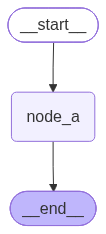

In [12]:
display(graph)

### 3.3.3 Overwrite绕过Reducer

通过节点的返回值来覆盖本次节点运行完毕后的 `State` 值。

* 需要注意的是，`Overwrite` 只影响当前这一次更新，并不会修改状态字段本身的 `Reducer` 定义。后续节点如果继续正常返回该字段的更新值，仍然会按照原来的 `Reducer` 逻辑进行合并。


In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add

class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str

def node_a(state: OverAllState):
    return {
        "logs": ["node_a new way home"]
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()


for chunk in graph.stream({"logs": ["START"], "id": "start"}, stream_mode="debug"):
    rprint(chunk)

{
    'step': 1,
    'timestamp': '2026-10-13T16:00:19.414106+00:00',
    'type': 'task',
    'payload': {
        'id': '9d9f3d6d-b609-2e55-646f-3a3e75e81ffd',
        'name': 'node_a',
        'input': {'logs': ['START'], 'id': 'start'},
        'triggers': ('branch:to:node_a',)
    }
}

{
    'step': 1,
    'timestamp': '2026-10-13T16:00:19.417172+00:00',
    'type': 'task_result',
    'payload': {
        'id': '9d9f3d6d-b609-2e55-646f-3a3e75e81ffd',
        'name': 'node_a',
        'error': None,
        'result': {'logs': ['node_a new way home']},
        'interrupts': []
    }
}

In [15]:
def reducer_add(left: str,right: str) -> str:
    """
    合并两个字符串，返回一个字符串，字符串之间用 "->" 连接

    Args:
        left: 从最开始的位置合并到当前节点位置的值，即当前已累计的状态值
        right: 当前节点的值，即本次待合并的新值

    """
    return left + "->" + right

from langgraph.graph import StateGraph, START, END
from typing import  Annotated
from operator import add
from langgraph.types import Overwrite
from dataclasses import dataclass
from rich import print as rprint

@dataclass
class OverAllState:
    logs: Annotated[list[str], add]
    cur_id: Annotated[str, reducer_add]

def node_1(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {# 自动转换为 OverAllState
        "logs": ["node_1 运行完毕"],
        "cur_id": "node_1"
    }

def node_2(state: OverAllState) -> OverAllState:
    pre_id = state.cur_id
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": Overwrite("node_2")
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", END)

graph = builder.compile()

rprint(graph.invoke({"cur_id": "start"}))
# 原输出: {'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': '->start->node_1->node_2'}
for chunk in graph.stream({"cur_id": "start"}, stream_mode="debug"):
    rprint(chunk)

{'logs': ['node_1 运行完毕', 'node_2 运行完毕'], 'cur_id': 'node_2'}

{
    'step': 1,
    'timestamp': '2026-10-13T16:14:29.690761+00:00',
    'type': 'task',
    'payload': {
        'id': 'bb37461c-3417-66ad-5948-88bd17a80456',
        'name': 'node_1',
        'input': OverAllState(logs=[], cur_id='->start'),
        'triggers': ('branch:to:node_1',)
    }
}

{
    'step': 1,
    'timestamp': '2026-10-13T16:14:29.692944+00:00',
    'type': 'task_result',
    'payload': {
        'id': 'bb37461c-3417-66ad-5948-88bd17a80456',
        'name': 'node_1',
        'error': None,
        'result': {'logs': ['node_1 运行完毕'], 'cur_id': 'node_1'},
        'interrupts': []
    }
}

{
    'step': 2,
    'timestamp': '2026-10-13T16:14:29.693038+00:00',
    'type': 'task',
    'payload': {
        'id': 'e94fdf5e-b6c2-30df-525c-cba6177d7dd4',
        'name': 'node_2',
        'input': OverAllState(logs=['node_1 运行完毕'], cur_id='->start->node_1'),
        'triggers': ('branch:to:node_2',)
    }
}

{
    'step': 2,
    'timestamp': '2026-10-13T16:14:29.696175+00:00',
    'type': 'task_result',
    'payload': {
        'id': 'e94fdf5e-b6c2-30df-525c-cba6177d7dd4',
        'name': 'node_2',
        'error': None,
        'result': {'logs': ['node_2 运行完毕'], 'cur_id': Overwrite(value='node_2', type='__overwrite__')},
        'interrupts': []
    }
}

# 结论
1. langgraph 通过注解的 2号参数 定义 state 合并的方式。
2. 默认采用 新值覆盖旧值的 方式更新 state
3. 初始输入(即空字符串)也会经过 reducer。
4. 并行更新的合并顺序由节点名决定.

# 问题
1. 当 创建的 `agent`  invoke 不指定 config 的 thread_id 和 短期记忆 时，会出现之前的记录遗忘的现象，是否是因为 Reducer?

结论: agent在 第一次调用后，内存中不保留有 运行节点后的 `state`。但是第二次调用不会自动继承第一次的 State。

```python
config = {"configurable": {"thread_id": "学习会话-1"}}

agent.invoke(
    {"messages": [{"role": "user", "content": "我叫小王"}]},
    config=config,
)

result = agent.invoke(
    {"messages": [{"role": "user", "content": "我叫什么名字？"}]},
    config=config,
)
```

配置短期记忆后，第二次调用的过程变为如下，这是官方说明的短期记忆机制。

```text
通过 thread_id 和 checkpointer 找到已保存的 State
        ↓
恢复历史 messages
        ↓
使用 add_messages 合并本次的新消息
        ↓
模型读取合并后的消息并回复
        ↓
保存更新后的 State
```


2. `3.3.3` 的for 循环输出。step = 1 的 `'type': 'task_result'` 的 chunk，result 的 cur_id 为什么 是 node_1 而不是  ->start->node_1?

结论: 因为 task_result 报告的是节点自己写出的更新（write），而不是合并后的状态（state）.reducer_add 不是节点自己调的，它是框架在图跑完这一步之后统一调用的。

### 三类 state 对照表

以 `3.3.3` 的图（`node_1` → `node_2`，`cur_id: Annotated[str, reducer_add]`，`logs: Annotated[list[str], add]`）为例：

| 名称 | 含义 | 在哪能观察到 | 示例值 |
| ---- | ---- | ------------ | ------ |
| **节点输入 state** | 本步开始时框架传给节点的状态，已经过 reducer 合并 | `task.payload.input` | `node_1` 拿到 `cur_id='->start'`；`node_2` 拿到 `cur_id='->start->node_1'` |
| **节点写入 write** | 节点 `return` 的字段更新，尚未经过 reducer | `task_result.payload.result` | `cur_id='node_1'` |
| **合并后 state** | reducer 作用之后的状态，也是下一步的输入 | 下一步的 `task.payload.input`、`stream_mode='values'`、`invoke` 返回值 | `cur_id='->start->node_1'` |

说明：

1. `task_result` 报告的是节点自己写出的更新（write），此时 reducer 还没有运行；`reducer_add` 不是节点自己调的，是框架在图跑完一步之后（`apply_writes`）统一调用的。
2. `logs` 表现一致：`result` 里只有本次写入的那一项，只有合并后 state 才会包含历史累积值。
3. 并行扇出（`node_1` → `node_2` / `node_1` → `node_3`）时，`node_2` 与 `node_3` 的 `task.payload.input` 相同（都拿到同一份合并后状态），各自的 `task_result` 仍是自己的原始写入，最后在同一个 `apply_writes` 里按 reducer 逐个合并。